# Impact de la taille des chunks et de l'overlap sur les performances d'un
---

### Résumé
Dans un système RAG (*Retrieval-Augmented Generation*), les documents sont découpés en morceaux (*chunks*) avant d'être indexés. Ce choix, souvent fait « au hasard » (512 tokens, 10 % d'overlap…), conditionne pourtant ce que le LLM verra. Nous étudions **de manière contrôlée** l'effet de deux hyperparamètres — **la taille des chunks** (64 → 1024 tokens) et **le taux de chevauchement** (0 → 50 %) — sur trois niveaux : (1) la **couverture** intrinsèque des réponses, (2) la **qualité de la recherche** (Hit@k, MRR) et (3) la **qualité des réponses générées** par un LLM (EM, F1, hallucinations), ainsi que (4) le **coût** (taille d'index, tokens de prompt, latence).
Point méthodologique central : nous comparons les configurations **à k fixe** *et* **à budget de tokens fixe**, car comparer des chunks de 64 et de 1024 tokens à k égal revient à donner 16 fois plus de texte au second.

**Principaux résultats.** (i) Contrairement à nos hypothèses initiales, **les petits chunks (64 tokens) dominent** à k fixe comme à budget fixe : Hit@budget de 93,8 % contre 39,4 % à 1 024 tokens. (ii) **25 % d'overlap** apporte +6,8 pts de recherche et +6,9 pts de F1 à 64 tokens, pour +33 % d'index. (iii) La **dilution sémantique est propre au retrieval dense** : BM25 reste stable jusqu'à 256 tokens. (iv) La qualité des réponses suit exactement la qualité de la recherche (Spearman = 1,0) : F1 de 66,4 contre 15,1 sans RAG et 80,8 avec l'oracle, avec des hallucinations ramenées de 84 % à ~2 %.


## 1. Introduction et problématique

### 1.1 Contexte
Les LLM ont des connaissances figées à leur date d'entraînement et peuvent **halluciner** (produire une réponse plausible mais fausse). Le RAG (Lewis et al., 2020) atténue ce problème : pour chaque question, on **récupère** des passages pertinents dans une base documentaire, puis on les injecte dans le prompt du LLM qui **génère** sa réponse en s'appuyant dessus.

Avant toute recherche, il faut découper les documents en **chunks**. Ce découpage est un compromis :
- **chunks petits** → représentation précise (un chunk ≈ une idée), peu de bruit dans le prompt, mais risque de **couper l'information** et de perdre le contexte nécessaire à la compréhension (pronoms, référents) ;
- **chunks grands** → contexte riche, mais l'embedding d'un long texte « moyenne » plusieurs idées (**dilution sémantique**), le prompt contient plus de texte non pertinent (**distraction**, Shi et al., 2023), et le coût augmente ;
- **l'overlap** (chevauchement entre chunks consécutifs) réduit le risque qu'une réponse soit coupée à une frontière, au prix d'un index plus gros et de redondance.

### 1.2 Problématique
> **Comment la taille des chunks et le taux d'overlap influencent-ils la qualité de la recherche, la qualité des réponses d'un LLM et le coût d'un système RAG — et existe-t-il une configuration optimale à budget de contexte fixé ?**

### 1.3 Hypothèses testées
- **H1 (biais du k fixe)** — À nombre de chunks k fixé, le Hit@k augmente avec la taille des chunks, simplement parce que plus de texte est récupéré. Cette comparaison est donc biaisée.
- **H2 (optimum à budget fixe)** — À budget de tokens fixé, la relation taille ↔ qualité de recherche est **non monotone** : il existe une taille intermédiaire optimale.
- **H3 (overlap)** — L'overlap réduit le taux de réponses coupées aux frontières (effet prédit par un modèle probabiliste simple, § 3.6), avec un gain surtout visible pour les petits chunks, et un coût d'index en 1/(1−r).
- **H4 (frontières sémantiques)** — Un découpage respectant les phrases fait au moins aussi bien qu'un découpage à taille fixe de même taille.
- **H5 (génération)** — La qualité des réponses (F1) suit la qualité de la recherche, mais un contexte très fragmenté (beaucoup de petits chunks) ou très bruité peut dégrader la génération et favoriser les hallucinations.

### 1.4 Contributions
1. Un banc d'essai **reproductible** évaluant 30 configurations de chunking (2 stratégies × 5 tailles × jusqu'à 4 overlaps).
2. Une métrique de recherche **exacte** basée sur la position (offsets) de la réponse, sans juge LLM.
3. Une comparaison **à k fixe vs à budget fixe**, avec intervalles de confiance bootstrap.
4. Une évaluation de bout en bout avec un LLM open-source (Qwen2.5-1.5B-Instruct), 3 baselines, une ablation de prompting et une **typologie des erreurs** (échec de recherche, échec de lecture, abstention, hallucination).

## 2. Bref état de l'art

**RAG.** Lewis et al. (2020) combinent un retriever dense (DPR) et un générateur seq2seq ; le RAG est devenu l'architecture standard pour ancrer un LLM dans des connaissances externes (revue : Gao et al., 2023).

**Retrieval sparse vs dense.** BM25 (Robertson & Zaragoza, 2009) classe les passages par recouvrement lexical pondéré ; les retrievers denses (Karpukhin et al., 2020) encodent question et passage dans un même espace vectoriel. DPR découpait Wikipédia en **passages de 100 mots sans overlap**, un choix de granularité repris par de nombreux travaux. Nous utilisons ici BGE-small (Xiao et al., 2023), un encodeur dense compact et performant.

**Granularité et chunking.**
- *Taille fixe* (avec ou sans overlap) : approche par défaut des frameworks (LangChain, LlamaIndex).
- *Découpage par phrases / récursif* : respecte les frontières linguistiques.
- *Propositions* : Chen et al. (2023, *Dense X Retrieval*) montrent que des unités plus fines que le passage (propositions atomiques) peuvent améliorer la recherche et la QA en aval à budget de mots fixe — c'est le résultat le plus proche de notre étude.
- *Late chunking* (Günther et al., 2024) : on encode d'abord le document entier puis on agrège par chunk, pour garder le contexte global dans chaque embedding.
- Wang et al. (2024) étudient empiriquement les « bonnes pratiques » du RAG, dont la taille des chunks, et observent que des tailles intermédiaires offrent le meilleur compromis entre fidélité et pertinence.

**Utilisation du contexte par les LLM.** Liu et al. (2024, *Lost in the Middle*) montrent que les LLM exploitent mal l'information placée au milieu d'un long contexte ; Shi et al. (2023) montrent qu'un contexte non pertinent dégrade les réponses. Ces deux effets pénalisent les configurations qui injectent beaucoup de texte.

**Évaluation.** Pour la QA extractive : Exact Match et F1 sur tokens (Rajpurkar et al., 2016). Pour le RAG : métriques de recherche (Hit@k, MRR) et de fidélité au contexte (RAGAS, Es et al., 2023).

**Positionnement.** Beaucoup de comparaisons de chunking publiées (souvent dans des blogs techniques) varient la taille à **k fixe**, ce qui confond l'effet de la granularité avec celui de la quantité de texte. Notre travail (i) contrôle le **budget de tokens**, (ii) mesure la **couverture** des réponses de façon exacte grâce aux offsets de SQuAD et la confronte à un **modèle probabiliste analytique**, et (iii) relie la recherche à la génération via une typologie d'erreurs.

## 3. Notions nouvelles (explications pédagogiques)

### 3.1 Token et tokenizer
Un modèle ne lit pas des mots mais des **tokens** (sous-mots). « *chunking* » peut devenir `chunk` + `##ing`. Toutes nos tailles sont exprimées **en tokens du tokenizer de l'encodeur**, ce qui garantit que « 256 tokens » correspond exactement à ce que l'encodeur voit. Nous utilisons l'option `return_offsets_mapping` qui donne, pour chaque token, sa position (début, fin) en caractères dans le texte : c'est ce qui permet de savoir exactement si une réponse est contenue dans un chunk.

### 3.2 Chunk, taille *s* et overlap *o*
```
texte  : t1 t2 t3 t4 t5 t6 t7 t8 t9 t10 t11 t12 ...
s=6, o=0 : [t1 … t6] [t7 … t12] ...            pas (step) = s − o = 6
s=6, o=2 : [t1 … t6]
                 [t5 … t10]
                         [t9 … t14] ...        pas = 4
```
Le **taux d'overlap** est r = o / s. Le nombre de chunks est multiplié par environ **1/(1 − r)** (×2 pour r = 50 %).

### 3.3 Embedding et similarité cosinus
Un **embedding** est un vecteur (ici 384 dimensions) qui résume le sens d'un texte. Deux textes proches en sens ont des vecteurs proches. On mesure la proximité par la **similarité cosinus** : cos(u, v) = u·v / (‖u‖‖v‖). Avec des vecteurs normalisés, c'est un simple produit scalaire. Limite importante : l'encodeur BGE-small ne lit que **512 tokens** maximum ; au-delà, le texte est **tronqué** (cela concernera nos chunks de 1024 tokens).

### 3.4 BM25 (baseline lexicale)
BM25 score un passage selon les mots de la question qu'il contient, pondérés par leur rareté (IDF) et normalisés par la longueur du passage. Pas d'apprentissage, pas de sémantique : il sert de baseline classique.

### 3.5 Métriques
- **Couverture** : % de questions dont la réponse est entièrement contenue dans au moins un chunk de l'index (indépendant de la recherche).
- **Hit@k** : % de questions pour lesquelles au moins un des k premiers chunks récupérés contient la réponse.
- **MRR** (*Mean Reciprocal Rank*) : moyenne de 1/rang du premier chunk pertinent (0 si absent du top-20). Récompense le fait de trouver la réponse **tôt**.
- **Exact Match (EM)** : la réponse normalisée (minuscules, sans ponctuation ni articles) est identique à une réponse de référence.
- **F1 token** : moyenne harmonique de la précision et du rappel des mots communs entre prédiction et référence — tolère les réponses partiellement correctes.
- **Hallucination (proxy)** : réponse fausse, non abstenue, **et non supportée par le contexte fourni** (moins de 80 % de ses mots présents dans le contexte).

### 3.6 Modèle probabiliste de coupure d'une réponse
Avec un découpage à taille fixe *s*, overlap *o* (pas d = s − o) et une réponse de *a* tokens à position uniformément aléatoire, la réponse est entièrement contenue dans un chunk si et seulement si un début de chunk tombe dans un intervalle de longueur s − a + 1. D'où :

$$P(\text{réponse coupée}) = \max\left(0,\ \frac{a - 1 - o}{s - o}\right)$$

Conséquences : (i) si o ≥ a − 1, aucune réponse n'est coupée ; (ii) l'effet de l'overlap est d'autant plus fort que *s* est petit. Nous confronterons cette prédiction aux données (§ 8.1).

### 3.7 k fixe vs budget fixe
À k = 5, des chunks de 64 tokens donnent 320 tokens de contexte, des chunks de 1024 en donnent 5 120. Pour une comparaison équitable, nous fixons aussi un **budget B = 1024 tokens** et prenons k = ⌊B / s⌋ chunks (16 chunks de 64, …, 1 chunk de 1024).

### 3.8 Intervalle de confiance par bootstrap
On ré-échantillonne avec remise les questions 1 000 fois et on recalcule la métrique ; les quantiles 2,5 % et 97,5 % donnent un IC à 95 %. Pour comparer deux configurations sur **les mêmes questions**, on fait un **bootstrap apparié** sur la différence (Efron & Tibshirani, 1993).

## Mise en place : installation, configuration et reproductibilité

In [1]:
!pip -q install datasets sentence-transformers rank_bm25 accelerate

In [2]:
import os, re, time, math, random, string, bisect, collections, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)

CONFIG = dict(
    seed=42,
    # --- modèles ---
    embed_model="BAAI/bge-small-en-v1.5",       # encodeur dense (384 dim, max 512 tokens)
    query_instruction="Represent this sentence for searching relevant passages: ",
    llm_model="Qwen/Qwen2.5-1.5B-Instruct",      # LLM générateur open-source
    # --- facteurs étudiés ---
    chunk_sizes=[64, 128, 256, 512, 1024],       # en tokens de l'encodeur
    overlap_ratios=[0.0, 0.10, 0.25, 0.50],      # r = o / s
    sentence_overlap_ratios=[0.0, 0.25],         # pour la stratégie "phrases"
    # --- recherche ---
    top_n=20,
    k_fixed=[1, 3, 5],
    token_budget=1024,
    n_questions_retrieval=1000,
    # --- génération ---
    n_questions_generation=200,
    gen_sizes=[64, 128, 256, 512],
    gen_overlaps=[0.0, 0.25],
    ablation_config=("fixed", 256, 0.25),        # fixé a priori (pas choisi sur les résultats)
    max_new_tokens=32,
    gen_batch_size=16,
    # --- statistiques ---
    n_bootstrap=1000,
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

set_seed(CONFIG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("results", exist_ok=True)

import transformers, sentence_transformers, datasets as hf_datasets
print(f"Python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} | "
      f"sentence-transformers {sentence_transformers.__version__} | datasets {hf_datasets.__version__}")
print("Device :", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

Python 3.13.15 | torch 2.11.0+cu130 | transformers 5.18.0 | sentence-transformers 5.7.0 | datasets 4.8.5
Device : cuda | Tesla T4


## 4. Données et préparation

### 4.1 Choix du dataset : SQuAD v1.1 (split validation)
- **Source :** https://huggingface.co/datasets/rajpurkar/squad (Rajpurkar et al., 2016), licence CC BY-SA 4.0.
- **Contenu :** 10 570 questions sur 2 067 paragraphes issus de **48 articles Wikipédia**, avec réponses extractives annotées (jusqu'à 3 annotateurs).
- **Pourquoi ce choix ?**
  1. Chaque réponse est donnée avec sa **position exacte** (`answer_start`) : on peut déterminer *sans juge LLM* si un chunk contient la réponse → métrique de recherche exacte et peu coûteuse.
  2. Réponses courtes et vérifiables → EM/F1 fiables pour évaluer la génération.
  3. Corpus de taille raisonnable pour tester 30 configurations sur un GPU gratuit.

### 4.2 Préparation : reconstruire de vrais documents
SQuAD fournit des paragraphes déjà découpés (~120 mots), ce qui **masquerait** l'effet du chunking. Nous **reconstituons chaque article** en concaténant ses paragraphes (séparés par `\n\n`) : 48 documents longs (plusieurs milliers de tokens) que nous découpons nous-mêmes. Les positions des réponses sont recalculées dans le document complet et **vérifiées** (le texte à la position calculée doit être exactement la réponse).

Le corpus de recherche est l'ensemble des 48 articles : pour chaque question, les chunks des 47 autres articles et ceux du même article servent de distracteurs.

In [3]:
def build_corpus(ds):
    # Reconstitue les articles complets et recalcule la position globale des réponses.
    titles, paras_by_title, para_index = [], {}, {}
    for ex in ds:
        t, c = ex["title"], ex["context"]
        if t not in paras_by_title:
            paras_by_title[t] = []; titles.append(t)
        if (t, c) not in para_index:
            para_index[(t, c)] = len(paras_by_title[t]); paras_by_title[t].append(c)

    SEP = "\n\n"
    docs, para_offsets = [], {}
    for d, t in enumerate(titles):
        off = 0
        for i, p in enumerate(paras_by_title[t]):
            para_offsets[(t, i)] = (d, off); off += len(p) + len(SEP)
        docs.append(dict(doc_id=d, title=t, text=SEP.join(paras_by_title[t])))

    questions, n_bad = [], 0
    for ex in ds:
        t, c = ex["title"], ex["context"]
        d, poff = para_offsets[(t, para_index[(t, c)])]
        spans = []
        for a_txt, a_st in zip(ex["answers"]["text"], ex["answers"]["answer_start"]):
            s, e = poff + a_st, poff + a_st + len(a_txt)
            if docs[d]["text"][s:e] == a_txt: spans.append((s, e))
            else: n_bad += 1
        if spans:
            questions.append(dict(qid=ex["id"], question=ex["question"],
                                  answers=list(dict.fromkeys(ex["answers"]["text"])),
                                  doc_id=d, spans=sorted(set(spans)), context=c))
    return docs, questions, n_bad

In [4]:
from datasets import load_dataset
squad = load_dataset("rajpurkar/squad", split="validation")
docs, all_questions, n_bad = build_corpus(squad)

print(f"Documents (articles) : {len(docs)}")
print(f"Questions valides    : {len(all_questions)} / {len(squad)}")
print(f"Spans de réponse rejetés (position incohérente) : {n_bad}")

# Échantillonnage aléatoire (graine fixée) ; les questions de génération sont un sous-ensemble
rng = np.random.default_rng(CONFIG["seed"])
perm = rng.permutation(len(all_questions))
q_ret = [all_questions[i] for i in perm[:CONFIG["n_questions_retrieval"]]]
q_gen = q_ret[:CONFIG["n_questions_generation"]]
print(f"Questions — recherche : {len(q_ret)} | génération : {len(q_gen)}")
print("\nExemple :", q_ret[0]["question"], "→", q_ret[0]["answers"])

README.md:   0%|          | 0.00/7.62k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 14.5MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 1.82MB            

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/87599 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10570 [00:00<?, ? examples/s]

Documents (articles) : 48
Questions valides    : 10570 / 10570
Spans de réponse rejetés (position incohérente) : 0
Questions — recherche : 1000 | génération : 200

Exemple : In what year did Massachusetts first require children to be educated in schools? → ['1852']


## 5. Méthodologie

### 5.1 Pipeline
```
Articles ──► Tokenisation (offsets) ──► Chunking (stratégie, s, r) ──► Embeddings BGE ──► Index
                                                                                    │
Question ──► Embedding (avec instruction BGE) ──► Similarité cosinus ──► Top-k chunks ┘
                                                                         │
                                       Prompt (contexte numéroté + question) ──► Qwen2.5-1.5B ──► Réponse
```

### 5.2 Facteurs étudiés (plan factoriel)
| Facteur | Niveaux |
|---|---|
| Stratégie | `fixed` (fenêtre glissante en tokens) · `sentence` (regroupement de phrases complètes) |
| Taille s | 64, 128, 256, 512, 1024 tokens |
| Overlap r | 0, 10, 25, 50 % (`fixed`) · 0, 25 % (`sentence`) |

→ 20 + 10 = **30 configurations** de recherche. Tout le reste (encodeur, questions, corpus, LLM, prompt) est **tenu constant** : seule la variable étudiée change.

### 5.3 Justification des choix techniques
- **Encodeur BGE-small-en-v1.5** : très bon rapport performance/coût sur le benchmark MTEB, 33 M de paramètres → on peut ré-indexer 30 fois le corpus sur un GPU gratuit. Sa limite de 512 tokens est assumée et **mesurée** (taux de troncature).
- **LLM Qwen2.5-1.5B-Instruct** : open-source (Apache 2.0), suit bien les instructions, tient sur un T4 en float16, **aucun coût d'API** et résultats **reproductibles** (décodage glouton). Un petit modèle est aussi plus sensible à la qualité du contexte, ce qui rend l'effet du chunking plus visible.
- **Prompting** : prompt « strict » qui (i) impose de répondre uniquement à partir du contexte, (ii) demande la phrase exacte la plus courte (adapté à la QA extractive et à l'EM/F1), (iii) autorise l'abstention (`unanswerable`) pour limiter les hallucinations. Les passages sont **numérotés** et classés par pertinence décroissante. Une ablation compare ce prompt à un prompt naïf.
- **Pas de fine-tuning** : l'objet d'étude est l'indexation, pas le modèle ; le fine-tuning introduirait un facteur confondant.

### 5.4 Baselines
1. **Closed-book** (LLM sans contexte) : mesure ce que le LLM sait déjà → borne basse, et montre l'apport du RAG.
2. **BM25** (même chunking) : baseline de recherche lexicale classique.
3. **Oracle** (paragraphe SQuAD d'origine fourni au LLM) : borne haute de la génération quand la recherche est parfaite.
4. **Configuration « par défaut »** de l'analyse : `fixed`, s = 256, r = 25 %, fixée *a priori*.

### 5.5 Métriques et protocole d'évaluation
| Niveau | Métriques | Pourquoi |
|---|---|---|
| Index | couverture, nb de chunks, taille d'index, taux de troncature | effet intrinsèque du découpage, coût |
| Recherche | Hit@1/3/5, MRR@20 (k fixe) ; Hit@budget, tokens de contexte (budget fixe) | qualité du retriever, comparaison équitable |
| Génération | EM, F1, taux d'abstention, taux d'hallucination, typologie d'erreurs | qualité finale perçue par l'utilisateur |
| Coût | tokens de prompt, temps d'indexation, latence de génération | faisabilité en production |

Incertitude : **IC 95 % par bootstrap** (1 000 ré-échantillonnages) et **bootstrap apparié** pour les comparaisons.

## 6. Implémentation

### 6.1 Métriques de QA (normalisation officielle SQuAD)

In [5]:
def normalize_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def f1_score(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    common = collections.Counter(p) & collections.Counter(g)
    n = sum(common.values())
    if n == 0: return 0.0
    prec, rec = n / len(p), n / len(g)
    return 2 * prec * rec / (prec + rec)

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def best_over_golds(fn, pred, golds):
    return max(fn(pred, g) for g in golds)

### 6.2 Stratégies de chunking
Les deux chunkers travaillent sur la liste des offsets de tokens d'un document et renvoient des triplets `(début_char, fin_char, nb_tokens)`. Le texte du chunk est obtenu par `doc[début:fin]`, sans perte.

In [6]:
def token_offsets(text, tokenizer):
    enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True, truncation=False)
    return [tuple(o) for o in enc["offset_mapping"]]

def chunk_fixed(offsets, size, overlap):
    # Fenêtre glissante de `size` tokens, avance de (size - overlap).
    assert 0 <= overlap < size
    step, n, spans, i = size - overlap, len(offsets), [], 0
    while i < n:
        j = min(i + size, n)
        spans.append((offsets[i][0], offsets[j - 1][1], j - i))
        if j == n: break
        i += step
    return spans

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])|\n\n")

def sentence_char_spans(text):
    spans, start = [], 0
    for m in SENT_SPLIT.finditer(text):
        if m.start() > start: spans.append((start, m.start()))
        start = m.end()
    if start < len(text): spans.append((start, len(text)))
    return spans

def chunk_sentence(offsets, text, size, overlap):
    # Regroupe des phrases complètes tant que le total <= size tokens.
    # Overlap : on recule d'autant de phrases entières que possible sans dépasser `overlap` tokens.
    starts = [o[0] for o in offsets]
    units = []
    for cs, ce in sentence_char_spans(text):
        i, j = bisect.bisect_left(starts, cs), bisect.bisect_left(starts, ce)
        if j <= i: continue
        if j - i <= size: units.append((i, j))
        else:  # phrase plus longue que le chunk : découpe fixe de secours
            units += [(a, min(a + size, j)) for a in range(i, j, size)]
    spans, cur = [], 0
    while cur < len(units):
        ntok, end = 0, cur
        while end < len(units) and ntok + (units[end][1] - units[end][0]) <= size:
            ntok += units[end][1] - units[end][0]; end += 1
        ti, tj = units[cur][0], units[end - 1][1]
        spans.append((offsets[ti][0], offsets[tj - 1][1], tj - ti))
        if end == len(units): break
        back, ov = end, 0
        while back - 1 > cur and ov + (units[back - 1][1] - units[back - 1][0]) <= overlap:
            back -= 1; ov += units[back][1] - units[back][0]
        cur = back
    return spans

def build_chunks(docs, doc_offsets, strategy, size, overlap_ratio):
    ov = int(round(overlap_ratio * size))
    rows = []
    for d in docs:
        offs = doc_offsets[d["doc_id"]]
        spans = chunk_fixed(offs, size, ov) if strategy == "fixed" else chunk_sentence(offs, d["text"], size, ov)
        rows += [(d["doc_id"], s, e, n) for s, e, n in spans]
    a = np.array(rows, dtype=np.int64)
    return dict(doc=a[:, 0], start=a[:, 1], end=a[:, 2], ntok=a[:, 3])

def chunk_texts(chunks, docs):
    return [docs[d]["text"][s:e] for d, s, e in zip(chunks["doc"], chunks["start"], chunks["end"])]

### 6.3 Pertinence exacte, couverture et modèle théorique
Un chunk est **pertinent** pour une question s'il appartient au bon article et contient **entièrement** l'un des spans de réponse de référence.

In [7]:
def relevance_matrix(top_idx, chunks, questions):
    rel = np.zeros(top_idx.shape, dtype=bool)
    for qi, q in enumerate(questions):
        idx = top_idx[qi]
        same = chunks["doc"][idx] == q["doc_id"]
        for s, e in q["spans"]:
            rel[qi] |= same & (chunks["start"][idx] <= s) & (chunks["end"][idx] >= e)
    return rel

def first_relevant_rank(rel):
    # Rang (1-based) du premier chunk pertinent ; inf si absent du top-N.
    has = rel.any(axis=1)
    return np.where(has, rel.argmax(axis=1) + 1, np.inf)

def coverage_flags(chunks, questions):
    # Pour chaque question : la réponse est-elle entièrement contenue dans AU MOINS un chunk de l'index ?
    by_doc = collections.defaultdict(list)
    for i, d in enumerate(chunks["doc"]): by_doc[int(d)].append(i)
    by_doc = {d: np.array(v) for d, v in by_doc.items()}
    out = np.zeros(len(questions), dtype=bool)
    for qi, q in enumerate(questions):
        idx = by_doc[q["doc_id"]]
        for s, e in q["spans"]:
            if np.any((chunks["start"][idx] <= s) & (chunks["end"][idx] >= e)):
                out[qi] = True; break
    return out

def answer_token_length(q, offsets):
    # Longueur (en tokens) du plus court span de réponse.
    starts = [o[0] for o in offsets]
    return min(bisect.bisect_left(starts, e) - bisect.bisect_right(starts, s) + 1 for s, e in q["spans"])

def theoretical_cut_prob(a, s, o):
    # P(réponse de a tokens coupée) pour un découpage fixe (taille s, overlap o) — cf. § 3.6
    return np.clip((np.asarray(a, float) - 1 - o) / (s - o), 0, 1)

### 6.4 Métriques de recherche et bootstrap

In [8]:
def retrieval_metrics(fr, ks, k_budget=None):
    m = {f"Hit@{k}": float(np.mean(fr <= k)) for k in ks}
    m["MRR@20"] = float(np.mean(np.where(fr <= 20, 1.0 / fr, 0.0)))
    if k_budget is not None: m["Hit@budget"] = float(np.mean(fr <= k_budget))
    return m

def bootstrap_ci(x, B=1000, alpha=0.05, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), (B, len(x)))].mean(axis=1)
    return x.mean(), np.quantile(means, alpha / 2), np.quantile(means, 1 - alpha / 2)

def paired_bootstrap(a, b, B=1000, seed=0):
    # Différence moyenne (a - b) sur les mêmes questions, IC 95 % et p-valeur unilatérale approx. P(diff <= 0).
    d = np.asarray(a, float) - np.asarray(b, float)
    rng = np.random.default_rng(seed)
    means = d[rng.integers(0, len(d), (B, len(d)))].mean(axis=1)
    return d.mean(), np.quantile(means, 0.025), np.quantile(means, 0.975), float(np.mean(means <= 0))

def fmt_ci(x, B=None):
    m, lo, hi = bootstrap_ci(x, B or CONFIG["n_bootstrap"])
    return f"{100*m:.1f} [{100*lo:.1f}–{100*hi:.1f}]"

def k_for_budget(size, budget):
    return max(1, budget // size)

### 6.5 Chargement de l'encodeur et tokenisation des documents

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (7170 > 512). Running this sequence through the model will result in indexing errors


Longueur max de l'encodeur : 512 tokens
Corpus : 329,916 tokens | doc moyen 6873 tokens (min 2935, max 17510)
Longueur des réponses : moyenne 3.1 tokens, médiane 2, P95 8


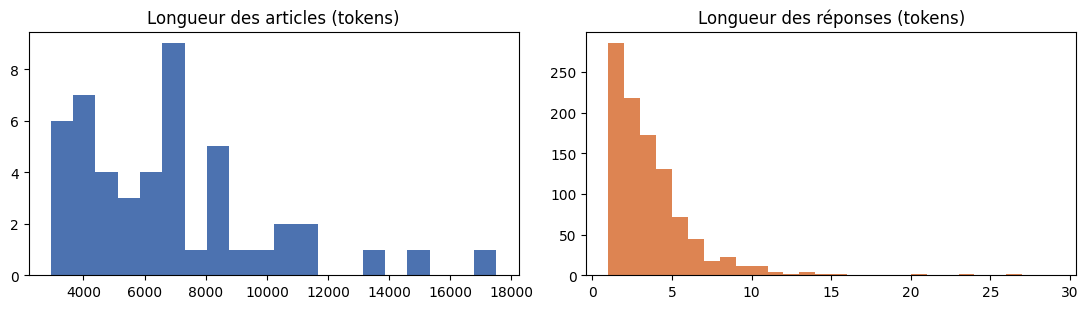

In [9]:
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer(CONFIG["embed_model"], device=device)
if device == "cuda": embedder.half()
emb_tok = embedder.tokenizer
MAX_SEQ = embedder.max_seq_length
print("Longueur max de l'encodeur :", MAX_SEQ, "tokens")

doc_offsets = {d["doc_id"]: token_offsets(d["text"], emb_tok) for d in docs}
doc_len = np.array([len(doc_offsets[d["doc_id"]]) for d in docs])
print(f"Corpus : {doc_len.sum():,} tokens | doc moyen {doc_len.mean():.0f} tokens (min {doc_len.min()}, max {doc_len.max()})")

ans_len = np.array([answer_token_length(q, doc_offsets[q["doc_id"]]) for q in q_ret])
print(f"Longueur des réponses : moyenne {ans_len.mean():.1f} tokens, médiane {np.median(ans_len):.0f}, P95 {np.percentile(ans_len,95):.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(doc_len, bins=20, color="#4C72B0"); ax[0].set_title("Longueur des articles (tokens)")
ax[1].hist(ans_len, bins=range(1, 30), color="#DD8452"); ax[1].set_title("Longueur des réponses (tokens)")
plt.tight_layout(); plt.savefig("results/eda.png", dpi=150); plt.show()

**Illustration** du découpage sur un petit extrait (s = 20, o = 5) : on voit que les 5 derniers tokens d'un chunk sont répétés au début du suivant, alors que la stratégie « phrases » ne coupe jamais une phrase.

In [10]:
demo = docs[0]["text"][:400]
demo_offs = token_offsets(demo, emb_tok)
print("— fixed, s=20, o=5 —")
for s, e, n in chunk_fixed(demo_offs, 20, 5)[:4]: print(f"[{n:>2} tok] {demo[s:e]!r}")
print("\n— sentence, s=40, o=0 —")
for s, e, n in chunk_sentence(demo_offs, demo, 40, 0)[:3]: print(f"[{n:>2} tok] {demo[s:e]!r}")

— fixed, s=20, o=5 —
[20 tok] 'Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL)'
[20 tok] 'Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion Denver Broncos'
[20 tok] 'AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to'
[20 tok] 'Panthers 24–10 to earn their third Super Bowl title. The game was played on February 7,'

— sentence, s=40, o=0 —
[25 tok] 'Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season.'
[32 tok] 'The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super Bowl title.'
[21 tok] "The game was played on February 7, 2016, at Levi's Stadium in the San Francisco Bay Area"


### 6.6 Fonctions de recherche (dense et BM25)

In [11]:
def encode(texts, bs=128):
    return embedder.encode(texts, batch_size=bs, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=False).astype(np.float32)

def top_n_dense(q_emb, c_emb, n):
    q = torch.from_numpy(q_emb).to(device); c = torch.from_numpy(c_emb).to(device)
    scores = q @ c.T
    return torch.topk(scores, k=min(n, c.shape[0]), dim=1).indices.cpu().numpy()

from rank_bm25 import BM25Okapi
TOK_RE = re.compile(r"\w+")
def bm25_tokens(t): return TOK_RE.findall(t.lower())

def top_n_bm25(questions, texts, n):
    bm25 = BM25Okapi([bm25_tokens(t) for t in texts])
    out = np.zeros((len(questions), n), dtype=np.int64)
    for i, q in enumerate(questions):
        sc = bm25.get_scores(bm25_tokens(q["question"]))
        top = np.argpartition(-sc, n)[:n]
        out[i] = top[np.argsort(-sc[top])]
    return out

# Les embeddings des questions ne dépendent pas du chunking : calculés une seule fois
t0 = time.time()
q_emb = encode([CONFIG["query_instruction"] + q["question"] for q in q_ret])
print(f"{len(q_ret)} questions encodées en {time.time()-t0:.1f}s")

1000 questions encodées en 2.0s


## 7. Protocole expérimental

| Exp. | Question posée | Ce qui varie | Ce qui est fixé | Sortie |
|---|---|---|---|---|
| **A — Couverture** | Le découpage coupe-t-il les réponses ? | s, r, stratégie | corpus, 1 000 questions | couverture vs prédiction théorique (§ 3.6) |
| **B — Recherche à k fixe** | Quelle config retrouve la réponse dans le top-k ? | s, r, stratégie | encodeur, k ∈ {1,3,5} | Hit@k, MRR |
| **C — Recherche à budget fixe** | Même question, à quantité de texte égale | s, r, stratégie, dense vs BM25 | B = 1 024 tokens | Hit@budget + IC 95 % |
| **D — Génération** | Les réponses du LLM suivent-elles ? | s ∈ {64…512}, r ∈ {0, 25 %} + 3 baselines | LLM, prompt strict, B = 1 024, 200 questions | EM, F1, abstention, hallucination |
| **E — Prompting** | Le prompt strict limite-t-il les hallucinations ? | prompt naïf vs strict | config (fixed, 256, 25 %) choisie a priori | EM, F1, hallucination |
| **F — Coût** | Que coûte chaque config ? | toutes | — | nb chunks, Mo d'index, temps, tokens de prompt |

**Contrôles de validité :**
- même échantillon de questions (graine 42) pour toutes les configurations → comparaisons **appariées** ;
- la configuration de l'ablation (E) et les configurations de génération (D) sont fixées **avant** de voir les résultats (pas de sur-ajustement sur l'ensemble de test) ;
- décodage **glouton** (`do_sample=False`) → génération déterministe ;
- les chunks de 1 024 tokens dépassent la fenêtre de l'encodeur (512) : ils sont **signalés** (`trunc_frac` = part des tokens non encodés) et interprétés à part.

## 8. Résultats

### 8.0 Exécution des 30 configurations de recherche (exp. A, B, C, F)

In [12]:
configs = [("fixed", s, r) for s in CONFIG["chunk_sizes"] for r in CONFIG["overlap_ratios"]] + \
          [("sentence", s, r) for s in CONFIG["chunk_sizes"] for r in CONFIG["sentence_overlap_ratios"]]

RUNS, rows = {}, []
B = CONFIG["token_budget"]
for strat, s, r in configs:
    t0 = time.time()
    ch = build_chunks(docs, doc_offsets, strat, s, r)
    texts = chunk_texts(ch, docs)
    t1 = time.time()
    c_emb = encode(texts, bs=256 if s <= 128 else 64)
    t_emb = time.time() - t1
    top = top_n_dense(q_emb, c_emb, CONFIG["top_n"])
    fr = first_relevant_rank(relevance_matrix(top, ch, q_ret))
    cov = coverage_flags(ch, q_ret)
    kb = k_for_budget(s, B)
    RUNS[(strat, s, r)] = dict(chunks=ch, top=top, fr=fr, cov=cov)
    rows.append(dict(strategy=strat, size=s, overlap=r, n_chunks=len(texts),
                     avg_tok=ch["ntok"].mean(), index_MB=c_emb.nbytes / 1e6, t_index_s=time.time() - t0,
                     trunc_frac=float(np.mean(np.maximum(0, ch["ntok"] + 2 - MAX_SEQ) / ch["ntok"])), coverage=cov.mean(),
                     k_budget=kb, **retrieval_metrics(fr, CONFIG["k_fixed"], kb)))
    print(f"{strat:8s} s={s:4d} r={r:.2f} | {len(texts):6d} chunks | cov {cov.mean():.3f} | "
          f"Hit@5 {rows[-1]['Hit@5']:.3f} | Hit@budget(k={kb}) {rows[-1]['Hit@budget']:.3f} | {time.time()-t0:.0f}s")
    del c_emb; torch.cuda.empty_cache() if device == "cuda" else None

df_ret = pd.DataFrame(rows)
df_ret.to_csv("results/retrieval_dense.csv", index=False)

fixed    s=  64 r=0.00 |   5179 chunks | cov 0.975 | Hit@5 0.788 | Hit@budget(k=16) 0.870 | 4s
fixed    s=  64 r=0.10 |   5705 chunks | cov 0.997 | Hit@5 0.812 | Hit@budget(k=16) 0.905 | 6s
fixed    s=  64 r=0.25 |   6879 chunks | cov 1.000 | Hit@5 0.851 | Hit@budget(k=16) 0.938 | 7s
fixed    s=  64 r=0.50 |  10285 chunks | cov 1.000 | Hit@5 0.876 | Hit@budget(k=16) 0.944 | 11s
fixed    s= 128 r=0.00 |   2602 chunks | cov 0.984 | Hit@5 0.787 | Hit@budget(k=8) 0.832 | 3s
fixed    s= 128 r=0.10 |   2891 chunks | cov 1.000 | Hit@5 0.808 | Hit@budget(k=8) 0.862 | 3s
fixed    s= 128 r=0.25 |   3445 chunks | cov 1.000 | Hit@5 0.856 | Hit@budget(k=8) 0.890 | 4s
fixed    s= 128 r=0.50 |   5131 chunks | cov 1.000 | Hit@5 0.851 | Hit@budget(k=8) 0.897 | 5s
fixed    s= 256 r=0.00 |   1314 chunks | cov 0.991 | Hit@5 0.790 | Hit@budget(k=4) 0.759 | 2s
fixed    s= 256 r=0.10 |   1455 chunks | cov 1.000 | Hit@5 0.794 | Hit@budget(k=4) 0.758 | 3s
fixed    s= 256 r=0.25 |   1726 chunks | cov 1.000 | Hi

### 8.1 Exp. A — Couverture : l'overlap protège-t-il les réponses ?

overlap,0.000000,0.100000,0.250000,0.500000
size,,,,
64,2.500000,0.300000,0.000000,0.000000
128,1.600000,0.000000,0.000000,0.000000
256,0.900000,0.000000,0.000000,0.000000
512,0.400000,0.000000,0.000000,0.000000
1024,0.300000,0.000000,0.000000,0.000000


overlap,0.000000,0.100000,0.250000,0.500000
size,,,,
64,3.310000,0.330000,0.040000,0.000000
128,1.650000,0.020000,0.000000,0.000000
256,0.830000,0.000000,0.000000,0.000000
512,0.410000,0.000000,0.000000,0.000000
1024,0.210000,0.000000,0.000000,0.000000


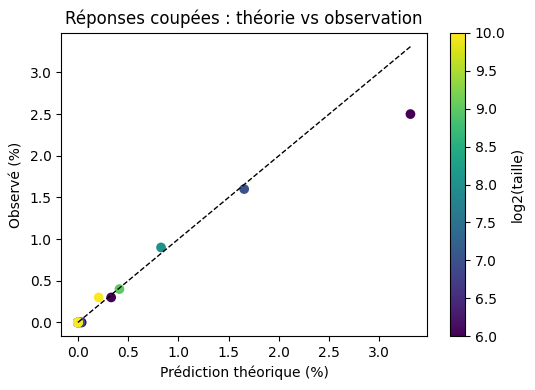

Corrélation théorie/observation : 0.99


In [13]:
fx = df_ret[df_ret.strategy == "fixed"].copy()
fx["cut_rate_emp"] = 1 - fx["coverage"]
fx["cut_rate_theo"] = [theoretical_cut_prob(ans_len, s, int(round(r * s))).mean() for s, r in zip(fx["size"], fx["overlap"])]

display((fx.pivot(index="size", columns="overlap", values="cut_rate_emp") * 100).round(2)
        .style.set_caption("Taux de réponses coupées (%) — empirique"))
display((fx.pivot(index="size", columns="overlap", values="cut_rate_theo") * 100).round(2)
        .style.set_caption("Taux de réponses coupées (%) — modèle théorique § 3.6"))

plt.figure(figsize=(5.5, 4))
plt.scatter(fx["cut_rate_theo"] * 100, fx["cut_rate_emp"] * 100, c=np.log2(fx["size"]), cmap="viridis")
m = max(fx["cut_rate_theo"].max(), fx["cut_rate_emp"].max()) * 100
plt.plot([0, m], [0, m], "k--", lw=1); plt.colorbar(label="log2(taille)")
plt.xlabel("Prédiction théorique (%)"); plt.ylabel("Observé (%)"); plt.title("Réponses coupées : théorie vs observation")
plt.tight_layout(); plt.savefig("results/coverage_theory.png", dpi=150); plt.show()
print("Corrélation théorie/observation :", np.corrcoef(fx["cut_rate_theo"], fx["cut_rate_emp"])[0, 1].round(3))


**Interprétation.** Sans overlap, 2,5 % des réponses sont coupées à 64 tokens (couverture 97,5 %), 1,6 % à 128, 0,9 % à 256 et au plus 0,4 % au-delà. Dès 25 % d'overlap, la couverture atteint **100 %** pour toutes les tailles. Le modèle du § 3.6 reproduit ces taux avec une **corrélation de 0,99** : connaître la longueur typique des réponses (médiane 2 tokens, P95 8 tokens) suffit à prévoir qu'un overlap de quelques tokens supprime le problème, sans expérience. Les petits écarts résiduels viennent de l'hypothèse de position uniforme et des fins de documents (dernier chunk plus court).

Ce gain de couverture reste toutefois **petit** (au plus +2,5 pts). Le § 8.3 montre que l'overlap améliore la recherche bien plus que ce que la couverture seule explique.


### 8.2 Exp. B — Recherche à k fixe

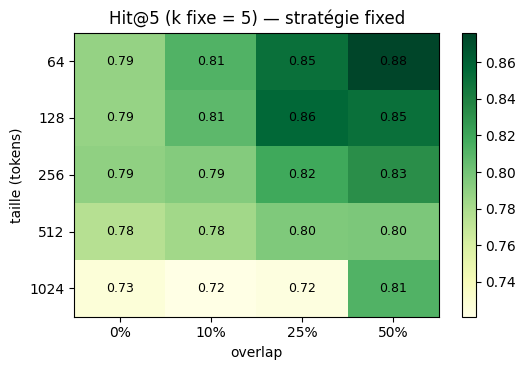

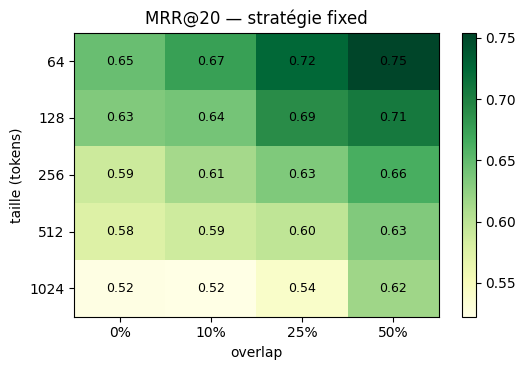

,strategy,size,overlap,Hit@1,Hit@3,Hit@5,MRR@20,trunc_frac
0,fixed,64,0.00,0.541,0.722,0.788,0.646,0.000e+00
1,fixed,64,0.10,0.566,0.750,0.812,0.675,0.000e+00
2,fixed,64,0.25,0.617,0.803,0.851,0.723,0.000e+00
3,fixed,64,0.50,0.659,0.829,0.876,0.754,0.000e+00
4,fixed,128,0.00,0.516,0.713,0.787,0.633,0.000e+00
5,fixed,128,0.10,0.509,0.735,0.808,0.640,0.000e+00
6,fixed,128,0.25,0.567,0.783,0.856,0.689,0.000e+00
7,fixed,128,0.50,0.590,0.795,0.851,0.706,0.000e+00
8,fixed,256,0.00,0.436,0.695,0.790,0.589,0.000e+00
9,fixed,256,0.10,0.473,0.711,0.794,0.613,0.000e+00


In [14]:
def heat(df, val, title, fname, fmt="{:.2f}"):
    p = df.pivot(index="size", columns="overlap", values=val)
    fig, ax = plt.subplots(figsize=(5.5, 3.8))
    im = ax.imshow(p.values, cmap="YlGn", aspect="auto")
    ax.set_xticks(range(len(p.columns)), [f"{int(c*100)}%" for c in p.columns])
    ax.set_yticks(range(len(p.index)), p.index)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]): ax.text(j, i, fmt.format(p.values[i, j]), ha="center", va="center", fontsize=9)
    ax.set_xlabel("overlap"); ax.set_ylabel("taille (tokens)"); ax.set_title(title)
    plt.colorbar(im); plt.tight_layout(); plt.savefig(f"results/{fname}", dpi=150); plt.show()

heat(fx, "Hit@5", "Hit@5 (k fixe = 5) — stratégie fixed", "heat_hit5.png")
heat(fx, "MRR@20", "MRR@20 — stratégie fixed", "heat_mrr.png")
display(df_ret[["strategy", "size", "overlap", "Hit@1", "Hit@3", "Hit@5", "MRR@20", "trunc_frac"]]
        .sort_values(["strategy", "size", "overlap"]).reset_index(drop=True))


**Interprétation — H1 réfutée.** Contrairement à l'intuition « plus de texte récupéré = plus de chances de trouver la réponse », à k fixe les **petits chunks font mieux** : Hit@5 = 0,85 à 64 tokens (r = 25 %) contre 0,80 à 512 et 0,72 à 1 024 ; le Hit@1 passe de 0,62 à 0,39 et le MRR de 0,72 à 0,54 (Spearman(taille, Hit@5) = −0,50, p = 0,047).

**Pourquoi ?** Récupérer plus de texte ne compense pas la perte de précision de l'embedding. Un chunk de 512 tokens mélange une vingtaine de phrases, et son vecteur en est une sorte de moyenne où la phrase contenant la réponse pèse peu : c'est la **dilution sémantique**. Les questions SQuAD sont factuelles et centrées sur une seule phrase, ce qui avantage la granularité fine, en cohérence avec Chen et al. (2023).

**Cas particulier des 1 024 tokens.** `trunc_frac` ≈ 0,46–0,49 : près de la moitié du texte n'est jamais encodée. Le saut observé à r = 50 % (Hit@5 de 0,72 à 0,81) est un **artefact de troncature**. Avec 50 % d'overlap, la seconde moitié (non encodée) de chaque chunk est la première moitié (encodée) du suivant, donc tout le texte est « vu » au moins une fois. Ce n'est pas un bénéfice propre de l'overlap.


### 8.3 Exp. C — Recherche à budget de tokens fixe (comparaison équitable)

,retriever,strategy,size,overlap,k,Hit@budget [IC95]
0,BM25,bm25,64,0.25,16,88.6 [86.6–90.6]
1,BM25,bm25,128,0.25,8,88.8 [86.9–90.8]
2,BM25,bm25,256,0.25,4,88.6 [86.7–90.5]
3,BM25,bm25,512,0.25,2,84.9 [82.8–87.1]
4,BM25,bm25,1024,0.25,1,76.1 [73.6–78.6]
5,dense,fixed,64,0.00,16,87.0 [85.0–89.0]
6,dense,fixed,64,0.10,16,90.5 [88.8–92.2]
7,dense,fixed,64,0.25,16,93.8 [92.3–95.3]
8,dense,fixed,64,0.50,16,94.4 [93.0–95.9]
9,dense,fixed,128,0.00,8,83.2 [80.8–85.6]


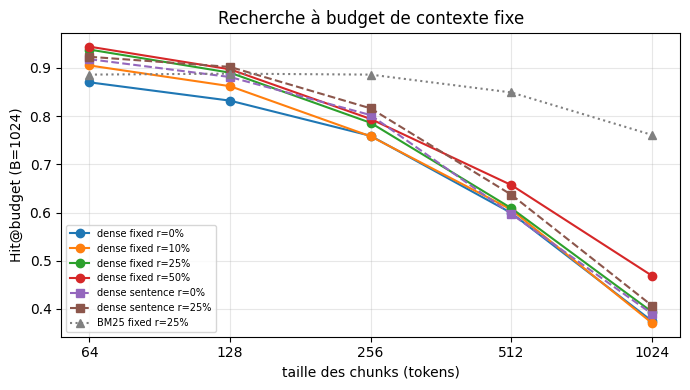

In [15]:
# BM25 sur le même chunking (overlap 25 %) comme baseline lexicale
bm_rows = []
for s in CONFIG["chunk_sizes"]:
    key = ("fixed", s, 0.25)
    ch = RUNS[key]["chunks"]
    t0 = time.time()
    top = top_n_bm25(q_ret, chunk_texts(ch, docs), CONFIG["top_n"])
    fr = first_relevant_rank(relevance_matrix(top, ch, q_ret))
    kb = k_for_budget(s, B)
    RUNS[("bm25", s, 0.25)] = dict(chunks=ch, top=top, fr=fr)
    bm_rows.append(dict(strategy="bm25", size=s, overlap=0.25, k_budget=kb,
                        **retrieval_metrics(fr, CONFIG["k_fixed"], kb), t_s=time.time() - t0))
df_bm25 = pd.DataFrame(bm_rows); df_bm25.to_csv("results/retrieval_bm25.csv", index=False)

# Tableau avec IC bootstrap
tab = []
for (strat, s, r), run in RUNS.items():
    kb = k_for_budget(s, B)
    tab.append(dict(retriever="BM25" if strat == "bm25" else "dense", strategy=strat, size=s, overlap=r, k=kb,
                    **{"Hit@budget [IC95]": fmt_ci(run["fr"] <= kb)}))
display(pd.DataFrame(tab).sort_values(["retriever", "strategy", "size", "overlap"]).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 4))
for r in CONFIG["overlap_ratios"]:
    d = fx[fx.overlap == r]; ax.plot(d["size"], d["Hit@budget"], "o-", label=f"dense fixed r={int(r*100)}%")
for r in CONFIG["sentence_overlap_ratios"]:
    d = df_ret[(df_ret.strategy == "sentence") & (df_ret.overlap == r)]
    ax.plot(d["size"], d["Hit@budget"], "s--", label=f"dense sentence r={int(r*100)}%")
ax.plot(df_bm25["size"], df_bm25["Hit@budget"], "^:", c="gray", label="BM25 fixed r=25%")
ax.set_xscale("log", base=2); ax.set_xticks(CONFIG["chunk_sizes"], CONFIG["chunk_sizes"])
ax.set_xlabel("taille des chunks (tokens)"); ax.set_ylabel(f"Hit@budget (B={B})")
ax.set_title("Recherche à budget de contexte fixe"); ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/hit_budget.png", dpi=150); plt.show()


**Interprétation.**
- **H2 réfutée : pas d'optimum intermédiaire.**
  - À r = 25 %, le Hit@budget décroît de façon monotone avec la taille : 93,8 % (64) → 89,0 % (128) → 78,6 % (256) → 60,9 % (512) → 39,4 % (1 024).
  - Toutes les différences avec 64 tokens sont significatives (bootstrap apparié, § 9.3).
  - À budget égal, 16 tirages précis valent mieux qu'un ou deux tirages dilués.
  - L'optimum se trouve au bord de la grille ; le § 8.7 teste donc 32 tokens.
- **L'overlap aide plus que la couverture ne l'explique.**
  - À 64 tokens, passer de 0 à 25 % d'overlap n'ajoute que +2,5 pts de couverture, mais **+6,8 pts de Hit@budget** [IC95 +4,8 ; +8,8].
  - L'overlap crée des fenêtres décalées, dont l'une est mieux « centrée » : la réponse y apparaît avec les mots de la question qui l'entourent, ce que l'embedding capte mieux.
  - Le gain diminue avec la taille et n'est plus significatif à partir de 512 tokens.
- **Phrases vs taille fixe (H4 partiellement confirmée).**
  - Le gain est significatif à 256 (+3,0 pts) et 512 tokens (+2,8 pts), mais pas à 64/128.
  - Sans overlap, couper aux frontières de phrases a presque le même effet qu'un overlap : Hit@1 = 0,63 (sentence 64, r = 0) contre 0,54 (fixed 64, r = 0).
- **Dense vs BM25.**
  - BM25 reste stable de 64 à 256 tokens (≈ 88,6 %), alors que le dense chute de 93,8 à 78,6 %. À 256 tokens, BM25 bat le dense de 10 pts.
  - La dilution est donc un phénomène **propre aux embeddings denses** : BM25 compte des termes exacts, qui restent présents quelle que soit la taille du chunk. Cela motive la recherche hybride (dense + BM25).
  - Nuance : les questions SQuAD ont été rédigées en lisant le paragraphe et reprennent son vocabulaire, ce qui favorise BM25.


### 8.4 Exp. D — Génération de bout en bout avec le LLM

In [16]:
from transformers import AutoTokenizer, AutoModelForCausalLM
llm_tok = AutoTokenizer.from_pretrained(CONFIG["llm_model"])
llm_tok.padding_side = "left"
if llm_tok.pad_token is None: llm_tok.pad_token = llm_tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(
    CONFIG["llm_model"], dtype=torch.float16 if device == "cuda" else torch.float32).to(device).eval()
print("LLM chargé :", CONFIG["llm_model"], f"({sum(p.numel() for p in llm.parameters())/1e9:.2f} B paramètres)")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM chargé : Qwen/Qwen2.5-1.5B-Instruct (1.54 B paramètres)


In [17]:
ABSTAIN = "unanswerable"
SYSTEM_STRICT = ("You are a careful question-answering assistant. Use ONLY the information in the numbered context passages. "
                 "Reply with the shortest exact phrase copied from the context (a few words, not a full sentence). "
                 f"If the context does not contain the answer, reply exactly: {ABSTAIN}")
SYSTEM_CLOSED = "Answer the question with the shortest possible phrase (a few words, not a full sentence)."

def build_messages(question, passages, mode):
    if mode == "closed_book":
        return [{"role": "system", "content": SYSTEM_CLOSED},
                {"role": "user", "content": f"Question: {question}\nAnswer:"}]
    ctx = "\n\n".join(f"[{i+1}] {p}" for i, p in enumerate(passages))
    if mode == "naive":
        return [{"role": "user", "content": f"Context:\n{ctx}\n\nQuestion: {question}\nAnswer:"}]
    return [{"role": "system", "content": SYSTEM_STRICT},
            {"role": "user", "content": f"Context:\n{ctx}\n\nQuestion: {question}\nAnswer:"}]

def clean_prediction(txt):
    txt = txt.strip().split("\n")[0].strip()
    txt = re.sub(r"^(answer\s*:\s*)", "", txt, flags=re.I)
    return txt.strip(" \"'").rstrip(".")

def is_supported(pred, context, thr=0.8):
    # Proxy de fidélité : >= 80 % des mots (normalisés) de la réponse apparaissent dans le contexte.
    p = normalize_answer(pred).split()
    if not p: return False
    ctx = set(normalize_answer(context).split())
    return np.mean([w in ctx for w in p]) >= thr

def categorize(pred, golds, context, ctx_has_answer):
    f1 = best_over_golds(f1_score, pred, golds)
    abst = ABSTAIN in pred.lower()
    if f1 >= 0.5: cat = "correcte"
    elif abst: cat = "abstention justifiée" if not ctx_has_answer else "abstention à tort"
    elif is_supported(pred, context): cat = "erreur de lecture" if ctx_has_answer else "mauvais passage (supportée)"
    else: cat = "hallucination"
    return f1, abst, cat

In [18]:
@torch.no_grad()
def generate(messages_list, bs=None):
    bs = bs or CONFIG["gen_batch_size"]; outs, n_prompt_tok = [], []
    for i in range(0, len(messages_list), bs):
        texts = [llm_tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in messages_list[i:i+bs]]
        enc = llm_tok(texts, return_tensors="pt", padding=True).to(device)
        n_prompt_tok += enc["attention_mask"].sum(1).tolist()
        gen = llm.generate(**enc, max_new_tokens=CONFIG["max_new_tokens"], do_sample=False,
                           temperature=None, top_p=None, top_k=None, pad_token_id=llm_tok.pad_token_id)
        outs += [clean_prediction(t) for t in llm_tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)]
    return outs, n_prompt_tok

def run_generation(name, source, mode):
    # source : clé de RUNS, "oracle" ou None (closed-book)
    msgs, ctxs, has_ans = [], [], []
    for qi, q in enumerate(q_gen):
        if source is None: passages, h = [], False
        elif source == "oracle": passages, h = [q["context"]], True
        else:
            run = RUNS[source]; k = k_for_budget(source[1], B)
            passages = chunk_texts({kk: v[run["top"][qi, :k]] for kk, v in run["chunks"].items()}, docs)
            h = bool(run["fr"][qi] <= k)
        msgs.append(build_messages(q["question"], passages, mode)); ctxs.append("\n".join(passages)); has_ans.append(h)
    t0 = time.time(); preds, ntok = generate(msgs); dt = time.time() - t0
    recs = []
    for q, p, c, h, n in zip(q_gen, preds, ctxs, has_ans, ntok):
        f1, abst, cat = categorize(p, q["answers"], c, h)
        recs.append(dict(run=name, qid=q["qid"], pred=p, golds=q["answers"], em=best_over_golds(exact_match, p, q["answers"]),
                         f1=f1, abstain=abst, hallu=(cat == "hallucination"), ctx_has_answer=h, category=cat, prompt_tok=n))
    print(f"{name:32s} | F1 {np.mean([r['f1'] for r in recs]):.3f} | {dt/len(q_gen)*1000:.0f} ms/question")
    return pd.DataFrame(recs).assign(latency_ms=dt / len(q_gen) * 1000)

GEN_PLAN = [("closed-book (sans RAG)", None, "closed_book"),
            ("oracle (paragraphe gold)", "oracle", "strict")]
GEN_PLAN += [(f"dense fixed s={s} r={int(r*100)}%", ("fixed", s, r), "strict")
             for s in CONFIG["gen_sizes"] for r in CONFIG["gen_overlaps"]]
s_ref, r_ref = CONFIG["ablation_config"][1], CONFIG["ablation_config"][2]
GEN_PLAN += [(f"dense sentence s={s_ref} r={int(r_ref*100)}%", ("sentence", s_ref, r_ref), "strict"),
             (f"BM25 fixed s={s_ref} r={int(r_ref*100)}%", ("bm25", s_ref, r_ref), "strict")]

gen_dfs = [run_generation(*p) for p in GEN_PLAN]

closed-book (sans RAG)           | F1 0.151 | 43 ms/question
oracle (paragraphe gold)         | F1 0.808 | 116 ms/question
dense fixed s=64 r=0%            | F1 0.595 | 338 ms/question
dense fixed s=64 r=25%           | F1 0.664 | 363 ms/question
dense fixed s=128 r=0%           | F1 0.583 | 345 ms/question
dense fixed s=128 r=25%          | F1 0.629 | 356 ms/question
dense fixed s=256 r=0%           | F1 0.503 | 338 ms/question
dense fixed s=256 r=25%          | F1 0.545 | 346 ms/question
dense fixed s=512 r=0%           | F1 0.429 | 345 ms/question
dense fixed s=512 r=25%          | F1 0.435 | 350 ms/question
dense sentence s=256 r=25%       | F1 0.557 | 331 ms/question
BM25 fixed s=256 r=25%           | F1 0.614 | 352 ms/question


In [19]:
def summarize(df):
    return pd.Series({"EM": fmt_ci(df.em), "F1": fmt_ci(df.f1), "F1_mean": df.f1.mean(),
                      "contexte contient la réponse %": 100 * df.ctx_has_answer.mean(),
                      "abstention %": 100 * df.abstain.mean(), "hallucination %": 100 * df.hallu.mean(),
                      "tokens prompt (moy.)": df.prompt_tok.mean(), "latence ms/q": df.latency_ms.iloc[0]})

gen_all = pd.concat(gen_dfs, ignore_index=True)
gen_all.to_csv("results/generation_predictions.csv", index=False)
df_gen = gen_all.groupby("run", sort=False).apply(summarize)
display(df_gen.drop(columns="F1_mean"))

,EM,F1,contexte contient la réponse %,abstention %,hallucination %,tokens prompt (moy.),latence ms/q
run,,,,,,,
closed-book (sans RAG),5.5 [2.5–9.0],15.1 [11.4–19.4],0.0,0.0,84.0,47.660,43.315
oracle (paragraphe gold),69.0 [62.0–75.0],80.8 [75.9–85.3],100.0,3.0,1.5,257.715,116.263
dense fixed s=64 r=0%,47.0 [40.0–53.5],59.5 [53.2–65.2],82.5,8.0,2.0,1233.030,337.833
dense fixed s=64 r=25%,54.5 [47.5–61.0],66.4 [60.6–72.4],91.5,6.0,2.0,1233.325,362.628
dense fixed s=128 r=0%,47.5 [40.5–54.0],58.3 [52.3–64.6],81.0,12.5,0.5,1184.400,345.189
dense fixed s=128 r=25%,54.0 [47.0–61.0],62.9 [57.0–68.9],87.0,10.0,2.0,1185.480,356.107
dense fixed s=256 r=0%,41.0 [34.5–47.5],50.3 [44.2–56.7],72.0,15.0,2.0,1165.770,338.320
dense fixed s=256 r=25%,45.0 [38.5–52.0],54.5 [48.3–61.1],74.5,11.5,2.0,1164.800,346.193
dense fixed s=512 r=0%,35.0 [28.5–41.5],42.9 [36.5–49.7],56.0,25.5,3.0,1147.020,345.388



**Interprétation.**
- **Apport du RAG :** le F1 passe de 15,1 (closed-book) à **66,4** avec la meilleure configuration (64 tokens, 25 %) ; l'oracle atteint 80,8. Le LLM de 1,5 B ne connaît pas ces détails factuels : sans contexte, 84 % de ses réponses sont des hallucinations.
- **H5, première partie, confirmée : la génération suit la recherche.** Le classement des configurations en F1 est identique à leur classement en « contexte contient la réponse » (Spearman = 1,0, § 9.3) : 64/25 % > 128/25 % > 64/0 % > 128/0 % > 256 > 512. L'overlap de 25 % ajoute +4 à +7 pts de F1 entre 64 et 256 tokens, et rien à 512.
- **H5, seconde partie, non observée :** recevoir 16 petits fragments ne dégrade pas la lecture. Le pire scénario est au contraire celui d'un ou deux grands chunks qui ne contiennent pas la réponse.
- **Écart à l'oracle :** avec la meilleure configuration, 91,5 % des contextes contiennent la réponse, mais seulement 68,5 % des réponses sont correctes. Les erreurs de lecture (≈ 18–20 %) varient peu d'une configuration à l'autre et existent déjà avec l'oracle (12 %). C'est donc d'abord une **limite du petit modèle**, aggravée d'environ 6 pts par un contexte ~5 fois plus long (≈ 1 200 tokens contre ≈ 260), ce qui est cohérent avec les effets de distraction (Shi et al., 2023 ; Liu et al., 2024).
- **BM25 en génération :** à 256 tokens, BM25 obtient un F1 de 61,4 contre 54,5 pour le dense, ce qui reflète sa meilleure recherche à cette taille.
- **Latence :** environ 340–360 ms par question pour toutes les configurations RAG (budget fixe), contre 116 ms pour l'oracle et 43 ms en closed-book. Le coût est piloté par le budget, pas par la taille des chunks.
- **Précision statistique :** avec 200 questions, les IC du F1 font environ ±6 pts. Les configurations voisines (par exemple 64/25 % et 128/25 %) ne sont pas séparables individuellement ; c'est la tendance d'ensemble qui est robuste.


### 8.5 Exp. E — Ablation du prompting (config fixée a priori)

In [20]:
src = CONFIG["ablation_config"]
abl = run_generation(f"PROMPT NAÏF {src}", src, "naive")
strict_name = f"dense fixed s={src[1]} r={int(src[2]*100)}%"
df_abl = pd.concat([gen_all[gen_all.run == strict_name], abl]).groupby("run", sort=False).apply(summarize)
display(df_abl.drop(columns="F1_mean"))

PROMPT NAÏF ('fixed', 256, 0.25) | F1 0.214 | 385 ms/question


,EM,F1,contexte contient la réponse %,abstention %,hallucination %,tokens prompt (moy.),latence ms/q
run,,,,,,,
dense fixed s=256 r=25%,45.0 [38.5–52.0],54.5 [48.3–61.1],74.5,11.5,2.0,1164.8,346.193
"PROMPT NAÏF ('fixed', 256, 0.25)",2.0 [0.5–4.5],21.4 [18.6–24.4],74.5,0.0,44.0,1124.8,385.156



**Interprétation — à lire avec prudence.** Le prompt strict multiplie le F1 par 2,5 (54,5 contre 21,4) et l'EM par plus de 20 (45 % contre 2 %). Mais l'essentiel de cet écart vient du **format** : sans consigne, le modèle répond par des phrases complètes, ce qui annule l'EM et fait baisser le F1 même quand l'information est juste.

De même, les 44 % d'« hallucinations » du prompt naïf sont **surestimés** : notre proxy (au moins 80 % des mots de la réponse présents dans le contexte) pénalise les phrases reformulées.

Ce qui reste solide : sans option d'abstention, le modèle répond toujours (0 % d'abstention), y compris quand le contexte ne contient pas la réponse (25,5 % des cas ici). Le prompt strict, lui, s'abstient dans ces situations au lieu d'inventer.

Pour séparer l'effet de fidélité de l'effet de format, il faudrait soit un juge NLI ou LLM, soit un post-traitement qui extrait la réponse courte de la phrase (voir perspectives).


### 8.6 Exp. F — Coûts

,size,overlap,n_chunks,index_MB,t_index_s,Hit@budget,facteur index vs r=0,1/(1-r) théorique
0,64,0.00,5179,7.955,4.408,0.870,1.000,1.000
1,64,0.10,5705,8.763,6.334,0.905,1.102,1.111
2,64,0.25,6879,10.566,6.867,0.938,1.328,1.333
3,64,0.50,10285,15.798,10.545,0.944,1.986,2.000
4,128,0.00,2602,3.997,2.691,0.832,1.000,1.000
5,128,0.10,2891,4.441,2.718,0.862,1.111,1.111
6,128,0.25,3445,5.292,3.758,0.890,1.324,1.333
7,128,0.50,5131,7.881,5.056,0.897,1.972,2.000
8,256,0.00,1314,2.018,2.423,0.759,1.000,1.000
9,256,0.10,1455,2.235,2.722,0.758,1.107,1.111


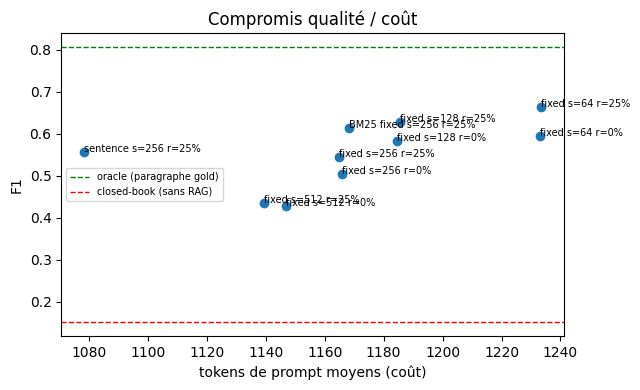

In [21]:
cost = df_ret[df_ret.strategy == "fixed"][["size", "overlap", "n_chunks", "index_MB", "t_index_s", "Hit@budget"]].copy()
cost["facteur index vs r=0"] = cost["n_chunks"] / cost.groupby("size")["n_chunks"].transform("first")
cost["1/(1-r) théorique"] = 1 / (1 - cost["overlap"])
display(cost.reset_index(drop=True))

g = df_gen.reset_index()
rag = g[g.run.str.startswith(("dense", "BM25"))]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(rag["tokens prompt (moy.)"], rag["F1_mean"])
for _, r in rag.iterrows(): ax.annotate(r["run"].replace("dense ", ""), (r["tokens prompt (moy.)"], r["F1_mean"]), fontsize=7)
for name, c in [("oracle (paragraphe gold)", "green"), ("closed-book (sans RAG)", "red")]:
    row = g[g.run == name].iloc[0]; ax.axhline(row["F1_mean"], ls="--", c=c, lw=1, label=name)
ax.set_xlabel("tokens de prompt moyens (coût)"); ax.set_ylabel("F1"); ax.legend(fontsize=7)
ax.set_title("Compromis qualité / coût"); plt.tight_layout(); plt.savefig("results/pareto.png", dpi=150); plt.show()


**Interprétation.**
- **Taille de l'index.** Le nombre de chunks suit bien la loi 1/(1 − r) : 1,27 à 1,33 observé pour r = 25 % (1,33 attendu). L'écart, un peu plus grand pour les grands chunks, vient du dernier chunk de chaque document.
- **Le bon compromis.** À 64 tokens, 25 % d'overlap coûte +33 % d'index (7,9 → 10,6 Mo) pour **+6,8 pts** de Hit@budget. Passer de 25 à 50 % ajoute encore +49 % d'index pour seulement +0,6 pt.
- **Passage à l'échelle.** Sur ce corpus, l'index reste petit (moins de 16 Mo). Pour des millions de documents, en revanche, la taille d'index devient le coût dominant, ce qui plaide pour un overlap de 25 % au plus.
- **Graphe qualité/coût.** Il discrimine peu sur l'axe horizontal : par construction (budget fixe), toutes les configurations RAG utilisent ≈ 1 100–1 230 tokens de prompt. Seul le F1 les distingue.


### 8.7 Expériences complémentaires

**(a) L'optimum est-il en dessous de 64 tokens ?** Le meilleur point de la grille (64 tokens) en est le bord inférieur. On teste donc 32 tokens, en `fixed` et en `sentence`, avec 0 et 25 % d'overlap. À budget B = 1 024, cela fait k = 32 chunks : on élargit le top-N en conséquence. Seules ces 4 configurations sont encodées (≈ 1 min).

In [ ]:
EXTRA = [("fixed", 32, 0.0), ("fixed", 32, 0.25), ("sentence", 32, 0.0), ("sentence", 32, 0.25)]
TOPN_EXTRA = max(CONFIG["top_n"], B // 32)
extra_rows = []
for strat, s, r in EXTRA:
    ch = build_chunks(docs, doc_offsets, strat, s, r)
    texts = chunk_texts(ch, docs)
    c_emb = encode(texts, bs=256)
    top = top_n_dense(q_emb, c_emb, TOPN_EXTRA)
    fr = first_relevant_rank(relevance_matrix(top, ch, q_ret))
    cov = coverage_flags(ch, q_ret)
    RUNS[(strat, s, r)] = dict(chunks=ch, top=top, fr=fr, cov=cov)
    kb = k_for_budget(s, B)
    extra_rows.append(dict(strategy=strat, size=s, overlap=r, n_chunks=len(texts), avg_tok=ch["ntok"].mean(),
                           index_MB=c_emb.nbytes / 1e6, coverage=cov.mean(), k_budget=kb,
                           **retrieval_metrics(fr, CONFIG["k_fixed"], kb)))
    del c_emb
    if device == "cuda": torch.cuda.empty_cache()
df_extra = pd.DataFrame(extra_rows)
df_extra.to_csv("results/retrieval_32tokens.csv", index=False)
display(df_extra)

print(f"Comparaison appariée 32 vs 64 tokens (Hit@budget, B={B}) :")
gains = []
for strat in ["fixed", "sentence"]:
    for r in [0.0, 0.25]:
        a = RUNS[(strat, 32, r)]["fr"] <= k_for_budget(32, B)
        b = RUNS[(strat, 64, r)]["fr"] <= k_for_budget(64, B)
        d, lo, hi, _ = paired_bootstrap(a, b)
        gains.append((d, lo, hi))
        verdict = "32 > 64 (sig.)" if lo > 0 else ("32 < 64 (sig.)" if hi < 0 else "pas de différence significative")
        print(f"  {strat:8s} r={int(r*100):2d}% : 32 → {100*a.mean():.1f} % | 64 → {100*b.mean():.1f} % | "
              f"Δ = {100*d:+.1f} pts [{100*lo:+.1f} ; {100*hi:+.1f}] → {verdict}")
n_pos = sum(lo > 0 for _, lo, _ in gains); n_neg = sum(hi < 0 for _, _, hi in gains)
if n_pos >= 3:
    print(f"\n→ 32 tokens fait mieux dans {n_pos}/4 cas : l'optimum est à une granularité de l'ordre de la phrase ou plus fine.")
elif n_neg >= 3:
    print(f"\n→ 64 tokens est un vrai optimum ({n_neg}/4 cas significatifs) : en dessous, les chunks manquent de contexte.")
else:
    print(f"\n→ Résultat mitigé ({n_pos} cas en faveur de 32, {n_neg} en faveur de 64) : plateau entre 32 et 64 tokens, "
          "alors que l'index double — 64 reste le meilleur compromis.")

**Lecture.** Deux effets s'opposent quand on descend sous 64 tokens :
- un chunk plus fin est plus précis, ce qui limite la dilution ;
- mais il porte moins de contexte (sujet, référents), si bien que son embedding devient plus ambigu.

Le résultat imprimé ci-dessus indique lequel domine sur SQuAD. Dans tous les cas, l'index double par rapport à 64 tokens : un gain non significatif ne justifierait pas ce coût.

**(b) L'avantage des petits chunks dépend-il du budget ?** On fait varier le budget de contexte B de 64 à 1 024 tokens. Ce balayage ne demande **aucun nouvel encodage** : les rangs du premier chunk pertinent sont déjà calculés. Pour chaque couple (taille, budget), on prend k = ⌊B / s⌋ chunks, et une taille est exclue si un seul chunk dépasse le budget.

In [ ]:
BUDGETS = [64, 128, 256, 512, 1024]
rows = []
for (strat, s, r), run in RUNS.items():
    for Bx in BUDGETS:
        k = Bx // s
        if k < 1 or k > run["top"].shape[1]: continue
        rows.append(dict(retriever="BM25" if strat == "bm25" else "dense", strategy=strat, size=s, overlap=r,
                         budget=Bx, k=k, hit=float(np.mean(run["fr"] <= k))))
sweep = pd.DataFrame(rows)
sweep.to_csv("results/budget_sweep.csv", index=False)

sel = sweep[(sweep.strategy == "fixed") & (sweep.overlap == 0.25)]
display((sel.pivot(index="size", columns="budget", values="hit") * 100).round(1)
        .style.set_caption("Hit@budget (%) — dense, fixed, overlap 25 % (lignes : taille, colonnes : budget)"))

fig, ax = plt.subplots(figsize=(7, 4))
for Bx in BUDGETS:
    d = sel[sel.budget == Bx].sort_values("size")
    ax.plot(d["size"], d["hit"] * 100, "o-", label=f"B = {Bx}")
ax.set_xscale("log", base=2); ax.set_xticks(sorted(sel["size"].unique()), sorted(sel["size"].unique()))
ax.set_xlabel("taille des chunks (tokens)"); ax.set_ylabel("Hit@budget (%)")
ax.set_title("Effet de la taille selon le budget de contexte (fixed, r = 25 %)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/budget_sweep.png", dpi=150); plt.show()

print("Meilleure taille par budget (dense, fixed, r=25 %) :")
for Bx in BUDGETS:
    d = sel[sel.budget == Bx]
    best = d.loc[d.hit.idxmax()]
    print(f"  B={Bx:5d} : s={int(best['size']):4d} (k={int(best.k)}) → {100*best.hit:.1f} %")

**Lecture.** On peut comparer les courbes de deux façons :
- **à taille fixe**, en lisant verticalement, on voit ce que rapporte un budget plus grand : c'est le compromis entre qualité et coût de génération ;
- **à budget fixe**, en lisant chaque courbe, on voit quelle granularité choisir.

Si la plus petite taille l'emporte à tous les budgets, l'avantage des petits chunks n'est pas un artefact de notre choix B = 1 024 : c'est le résultat le plus robuste de l'étude. Si l'optimum se déplace vers de plus grands chunks quand B est petit (peu de tirages possibles), la recommandation doit alors dépendre du budget disponible.

## 9. Analyse critique

### 9.1 Typologie des erreurs

category,correcte,abstention justifiée,abstention à tort,erreur de lecture,mauvais passage (supportée),hallucination
run,,,,,,
closed-book (sans RAG),16.0,0.0,0.0,0.0,0.0,84.0
oracle (paragraphe gold),83.5,0.0,3.0,12.0,0.0,1.5
dense fixed s=64 r=0%,62.5,4.0,4.0,19.0,8.5,2.0
dense fixed s=64 r=25%,68.5,1.5,4.5,18.0,5.5,2.0
dense fixed s=128 r=0%,61.5,6.5,6.0,17.0,8.5,0.5
dense fixed s=128 r=25%,64.0,6.5,3.5,19.5,4.5,2.0
dense fixed s=256 r=0%,51.5,11.5,3.5,19.0,12.5,2.0
dense fixed s=256 r=25%,56.0,9.5,2.0,20.0,10.5,2.0
dense fixed s=512 r=0%,43.5,23.0,2.5,13.5,14.5,3.0


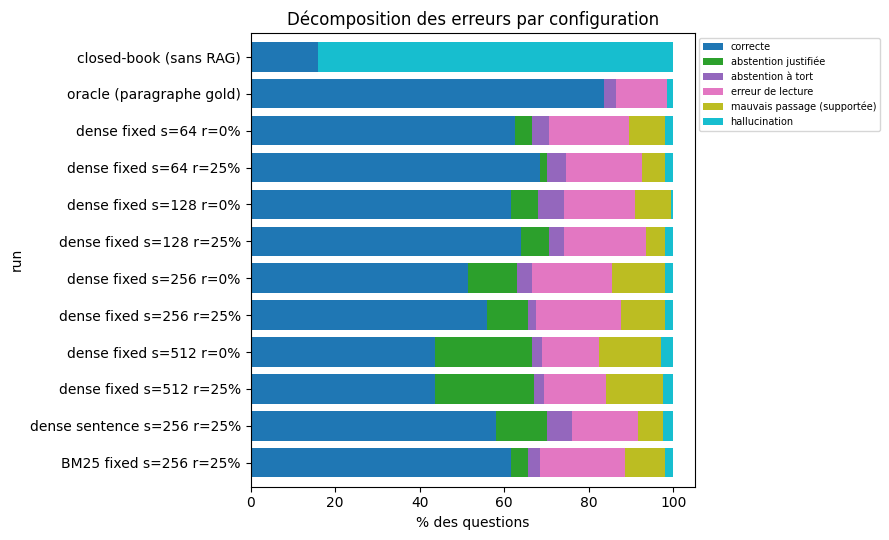

In [22]:
order = ["correcte", "abstention justifiée", "abstention à tort", "erreur de lecture", "mauvais passage (supportée)", "hallucination"]
ct = pd.crosstab(gen_all.run, gen_all.category, normalize="index").reindex(columns=order, fill_value=0) * 100
ct = ct.loc[[n for n in df_gen.index] + [n for n in ct.index if n not in df_gen.index]]
display(ct.round(1))
ax = ct.plot(kind="barh", stacked=True, figsize=(9, 5.5), colormap="tab10", width=.8)
ax.set_xlabel("% des questions"); ax.legend(fontsize=7, bbox_to_anchor=(1, 1)); ax.invert_yaxis()
plt.title("Décomposition des erreurs par configuration"); plt.tight_layout(); plt.savefig("results/errors.png", dpi=150); plt.show()

Lecture des catégories :
- **erreur de lecture** : la réponse était dans le contexte mais le LLM a extrait un autre fragment → problème du générateur (distraction, *lost in the middle*) ;
- **mauvais passage (supportée)** : le LLM a fidèlement extrait une réponse d'un passage non pertinent → problème du **retriever** ;
- **hallucination** : réponse ni correcte ni présente dans le contexte → le LLM a « inventé » (ou utilisé sa mémoire paramétrique).

**Lecture des résultats :**
- **Échecs du retriever.** Les « mauvais passages » passent de 5,5 % (64/25 %) à 13,5 % (512/25 %).
- **Abstentions.** Les abstentions justifiées augmentent avec la taille, de 1,5 % à 23,5 %. Quand la recherche échoue, le modèle s'abstient au lieu d'inventer, ce qui valide le prompt strict.
- **Hallucinations.** Elles restent entre 0,5 et 3 % pour toutes les configurations RAG, contre 84 % sans RAG.
- **Erreurs de lecture.** Avec 13 à 20 % des questions, elles sont la principale source d'erreur restante.


In [23]:
# Exemples qualitatifs (config par défaut)
ex = gen_all[gen_all.run == strict_name]
for cat in ["hallucination", "erreur de lecture", "abstention à tort"]:
    sub = ex[ex.category == cat].head(2)
    for _, r in sub.iterrows():
        q = next(q for q in q_gen if q["qid"] == r.qid)
        print(f"[{cat}] Q: {q['question']}\n   prédiction: {r.pred!r} | référence: {r.golds}\n")

[hallucination] Q: What kinds of growth did Kublai encourage?
   prédiction: 'centralization of the bureaucracy, expansion of paper money, maintenance of traditional monopolies on salt and iron, restoration of the Imperial Secretariat, leaving the local administrative' | référence: ['commercial, scientific, and cultural']

[hallucination] Q: What did Warsz own?
   prédiction: 'Warszownica' | référence: ['a village', 'village']

[erreur de lecture] Q: What Lake in a German island Mainau receives a fraction of the Rhine's flow?
   prédiction: 'Mainau' | référence: ['Lake Überlingen']

[erreur de lecture] Q: How many fraternities are apart of the university?
   prédiction: 'seven' | référence: ['fifteen']

[abstention à tort] Q: Who had established the Russian empire to its former glory prior to 1921?
   prédiction: 'unanswerable' | référence: ['Bolshevik leaders']

[abstention à tort] Q: What is the state average growth rate?
   prédiction: 'unanswerable' | référence: ['10.0%']



**Ce que montrent ces exemples.**
- **Erreurs de lecture.** Les vraies erreurs de lecture (« Mainau » au lieu de « Lake Überlingen », « seven » au lieu de « fifteen ») montrent que le modèle extrait une **entité voisine** de la bonne réponse dans le bon passage. C'est typique d'un petit modèle face à un contexte dense en entités.
- **Limites du proxy d'hallucination.** La réponse sur Kublai ressemble à une longue liste extraite d'un passage, coupée par la limite de 32 tokens générés. Elle est classée « hallucination » parce que moins de 80 % de ses mots sont retrouvés, alors qu'il s'agit plutôt d'une erreur de lecture. « Warszownica » est une quasi-copie d'un mot du contexte.
- **Conséquence.** Les taux d'hallucination doivent être lus comme des **ordres de grandeur**.

### 9.2 Erreurs et limites de la recherche

In [24]:
# Hit@budget par longueur de réponse : les longues réponses sont-elles pénalisées par les petits chunks ?
bins = pd.cut(ans_len, [0, 2, 4, 8, 1000], labels=["1–2", "3–4", "5–8", ">8"])
rows = {}
for s in CONFIG["chunk_sizes"]:
    for r in [0.0, 0.25]:
        fr = RUNS[("fixed", s, r)]["fr"]
        rows[f"s={s} r={int(r*100)}%"] = pd.Series(fr <= k_for_budget(s, B)).groupby(bins).mean() * 100
display(pd.DataFrame(rows).T.round(1).style.set_caption("Hit@budget (%) selon la longueur de la réponse (tokens)"))

,1–2,3–4,5–8,>8
s=64 r=0%,89.700000,86.800000,79.500000,83.800000
s=64 r=25%,93.600000,93.100000,94.900000,97.300000
s=128 r=0%,85.100000,81.900000,79.500000,83.800000
s=128 r=25%,89.300000,89.500000,87.200000,89.200000
s=256 r=0%,75.000000,79.300000,73.100000,73.000000
s=256 r=25%,75.300000,81.600000,82.100000,83.800000
s=512 r=0%,58.600000,60.500000,61.500000,64.900000
s=512 r=25%,60.000000,62.800000,59.000000,64.900000
s=1024 r=0%,38.200000,34.200000,38.500000,51.400000
s=1024 r=25%,40.400000,36.800000,38.500000,51.400000


### 9.3 Vérification des hypothèses (tests statistiques)

In [25]:
from scipy.stats import spearmanr
fx0 = fx[fx["size"] <= 512]
rho, p = spearmanr(fx0["size"], fx0["Hit@5"])
print(f"H1 — k fixe : Spearman(taille, Hit@5) = {rho:.2f} (p={p:.3f}) → "
      f"{'confirmée' if rho > 0 and p < .05 else 'non confirmée (tendance' + (' positive)' if rho > 0 else ' non positive)')}")

curve = fx[fx.overlap == 0].set_index("size")["Hit@budget"]
best_s = curve.idxmax()
inner = best_s not in (min(CONFIG["chunk_sizes"]), max(CONFIG["chunk_sizes"]))
print(f"H2 — budget fixe : meilleure taille = {best_s} tokens (Hit@budget={curve.max():.3f}) → "
      f"{'optimum intermédiaire, H2 confirmée' if inner else 'optimum en bord de grille, H2 non confirmée'}")
for s in CONFIG["chunk_sizes"]:
    if s == best_s: continue
    d, lo, hi, pv = paired_bootstrap(RUNS[("fixed", best_s, 0.0)]["fr"] <= k_for_budget(best_s, B),
                                     RUNS[("fixed", s, 0.0)]["fr"] <= k_for_budget(s, B))
    print(f"     {best_s} vs {s:4d} : Δ={100*d:+.1f} pts [IC95 {100*lo:+.1f} ; {100*hi:+.1f}] {'*' if lo > 0 else '(n.s.)'}")

print("H3 — overlap (gain de couverture 0 → 25 %, en points) :")
for s in CONFIG["chunk_sizes"]:
    c0 = fx[(fx["size"] == s) & (fx.overlap == 0)].coverage.item(); c25 = fx[(fx["size"] == s) & (fx.overlap == .25)].coverage.item()
    d, lo, hi, _ = paired_bootstrap(RUNS[("fixed", s, .25)]["fr"] <= k_for_budget(s, B), RUNS[("fixed", s, 0.0)]["fr"] <= k_for_budget(s, B))
    print(f"     s={s:4d} : couverture {100*(c25-c0):+.2f} pts | Hit@budget {100*d:+.1f} [{100*lo:+.1f};{100*hi:+.1f}]")

print("H4 — sentence vs fixed (r=25 %, Hit@budget) :")
for s in CONFIG["chunk_sizes"]:
    d, lo, hi, _ = paired_bootstrap(RUNS[("sentence", s, .25)]["fr"] <= k_for_budget(s, B), RUNS[("fixed", s, .25)]["fr"] <= k_for_budget(s, B))
    print(f"     s={s:4d} : Δ={100*d:+.1f} pts [{100*lo:+.1f};{100*hi:+.1f}] {'sentence > fixed (sig.)' if lo > 0 else ('sentence < fixed (sig.)' if hi < 0 else 'pas de différence significative')}")

rg = df_gen.loc[[n for n in df_gen.index if n.startswith("dense fixed")]]
r5, p5 = spearmanr(rg["contexte contient la réponse %"], rg["F1_mean"])
print(f"H5 — Spearman(Hit@budget, F1) sur les configs de génération = {r5:.2f} (p={p5:.3f})")

H1 — k fixe : Spearman(taille, Hit@5) = -0.50 (p=0.047) → non confirmée (tendance non positive)
H2 — budget fixe : meilleure taille = 64 tokens (Hit@budget=0.870) → optimum en bord de grille, H2 non confirmée
     64 vs  128 : Δ=+3.8 pts [IC95 +1.7 ; +6.3] *
     64 vs  256 : Δ=+11.1 pts [IC95 +8.4 ; +14.1] *
     64 vs  512 : Δ=+27.1 pts [IC95 +23.8 ; +30.6] *
     64 vs 1024 : Δ=+49.5 pts [IC95 +46.1 ; +52.8] *
H3 — overlap (gain de couverture 0 → 25 %, en points) :
     s=  64 : couverture +2.50 pts | Hit@budget +6.8 [+4.8;+8.8]
     s= 128 : couverture +1.60 pts | Hit@budget +5.8 [+3.9;+7.9]
     s= 256 : couverture +0.90 pts | Hit@budget +2.7 [+0.3;+5.3]
     s= 512 : couverture +0.40 pts | Hit@budget +1.0 [-1.8;+3.9]
     s=1024 : couverture +0.30 pts | Hit@budget +1.9 [-1.4;+4.9]
H4 — sentence vs fixed (r=25 %, Hit@budget) :
     s=  64 : Δ=-1.5 pts [-3.2;+0.2] pas de différence significative
     s= 128 : Δ=+1.2 pts [-0.6;+3.0] pas de différence significative
     s= 256 : Δ=+3


### 9.4 Discussion
1. **Plus petit = meilleur, sur ce type de questions.** Nos hypothèses H1 et H2 sont réfutées : la meilleure granularité est la plus fine testée, à k fixe comme à budget fixe (§ 8.7 pour 32 tokens). La valeur par défaut « 512 tokens » est à éviter pour de la QA factuelle avec un encodeur dense : elle coûte 33 pts de recherche et 23 pts de F1 par rapport à 64 tokens.
2. **L'overlap est une assurance bon marché pour les petits chunks.** Le modèle probabiliste prédit la couverture (r = 0,99). Mais le gain de recherche est trois fois plus grand que le gain de couverture : l'overlap agit surtout en donnant des fenêtres mieux centrées sur la réponse et son contexte. Au-delà de 256 tokens, il est inutile.
3. **La dilution est un problème du dense, pas du chunking en soi.** BM25 reste stable quand la taille augmente, alors que le dense chute fortement. Cela motive la recherche **hybride** et la stratégie *small-to-big* (rechercher sur de petits chunks, injecter un contexte plus large).
4. **La fenêtre de l'encodeur borne la taille utile.** Au-delà de 512 tokens, la moitié du texte n'est pas encodée, et l'amélioration apparente de 1 024/50 % est un artefact.
5. **La génération hérite de la recherche.** Le F1 suit exactement le Hit@budget. L'écart restant à l'oracle (~14 pts) vient surtout de la lecture par un modèle de 1,5 B et, dans une moindre mesure, de la longueur du contexte.
6. **Le RAG combiné au prompt strict réduit fortement les hallucinations** (de 84 % à ~2 %). Le modèle préfère s'abstenir quand la recherche échoue, ce qui est le comportement souhaité.
7. **Portée.** Ces conclusions valent pour des questions factuelles locales (une réponse dans une phrase). Pour des questions de synthèse ou multi-sauts, des chunks plus grands pourraient redevenir avantageux.


## 10. Limites et perspectives

**Limites**
- **Un seul dataset** (SQuAD, Wikipédia, anglais) avec réponses courtes et factuelles. Des questions nécessitant de combiner plusieurs passages (multi-hop, HotpotQA) ou des documents techniques/juridiques favoriseraient probablement des chunks plus grands.
- **Pertinence stricte** : un chunk qui contient la bonne réponse à un autre endroit que le span annoté est compté non pertinent → le Hit@k est une **borne basse**.
- **Proxy d'hallucination lexical** : une paraphrase fidèle peut être comptée « non supportée », et une réponse fausse composée de mots du contexte peut passer. Un juge LLM ou une vérification NLI (RAGAS) serait plus fin mais plus coûteux et lui-même faillible.
- **Un seul encodeur et un seul LLM**, de petite taille ; un LLM plus grand est plus robuste au bruit et exploiterait mieux les longs contextes.
- **Échantillon** : 1 000 questions (recherche) et 200 (génération) ; les IC bootstrap quantifient cette incertitude, mais certaines différences restent non significatives.
- **Budget unique** B = 1 024 ; l'optimum dépend probablement de B.
- Les questions SQuAD ont été écrites **en lisant le paragraphe**, d'où un fort recouvrement lexical question/passage qui avantage BM25 par rapport à des questions réelles.
- **Format et fidélité confondus dans l'ablation du prompt** : le proxy lexical pénalise les réponses longues ou reformulées du prompt naïf. L'écart de 44 % d'hallucinations est donc surestimé.
- **Taille de génération limitée** : avec 200 questions, les IC du F1 font environ ±6 pts, et les configurations voisines ne sont pas séparables individuellement.
- **Artefact de troncature** à 1 024 tokens (seuls 512 tokens sont encodés). Ces résultats ne mesurent pas un « vrai » chunk de 1 024 tokens.

**Perspectives**
- Recherche **hybride** (BM25 + dense), motivée par la robustesse de BM25 aux grands chunks.
- Post-traitement d'extraction de réponse courte et juge NLI pour mieux mesurer la fidélité.
- Encodeurs à longue fenêtre (8k tokens) pour lever la troncature ; *late chunking* (Günther et al., 2024).
- Chunking sémantique (frontières par rupture de similarité) et par propositions (Chen et al., 2023).
- **Small-to-big / parent document retrieval** : rechercher avec de petits chunks (précis) mais injecter le chunk parent plus grand (contexte) — combine les avantages observés.
- Reranking par cross-encoder sur un top-k plus large.
- Évaluer sur un corpus français et sur des documents métier.


## 11. Conclusion
Nous avons évalué 30 configurations de chunking (plus 4 configurations à 32 tokens) sur un corpus Wikipédia reconstitué à partir de SQuAD. L'évaluation porte sur trois niveaux (couverture, recherche, génération) et tient compte du coût. Quatre enseignements :
1. **La granularité fine gagne.** Sur des questions factuelles, des chunks de 64 tokens surpassent nettement les tailles usuelles, à k fixe comme à budget fixe : Hit@budget de 93,8 % contre 60,9 % à 512 tokens, et F1 de 66,4 contre 43,5. La raison principale est la dilution sémantique des embeddings denses ; BM25, lui, y est peu sensible.
2. **L'overlap sert surtout les petits chunks.** Avec 25 % d'overlap, on gagne +6,8 pts de recherche et +6,9 pts de F1 à 64 tokens, pour +33 % d'index. Son effet sur la couverture est prédit par un modèle probabiliste simple (corrélation 0,99). Au-delà de 256 tokens, l'overlap ne rapporte presque plus rien.
3. **La qualité finale suit la qualité de la recherche** (Spearman = 1,0). Le RAG fait passer le F1 de 15 à 66 et les hallucinations de 84 % à ~2 % grâce à un prompt strict avec abstention. L'écart restant à l'oracle tient surtout aux limites de lecture d'un petit LLM.
4. **Recommandation pratique.** Pour de la QA factuelle avec un encodeur dense : des chunks courts (64–128 tokens), environ 25 % d'overlap ou des frontières de phrases, une taille inférieure à la fenêtre de l'encodeur, et une recherche hybride si les chunks doivent rester longs. Ces choix sont à valider sur un échantillon annoté du domaine cible.


## 12. Références
1. Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.* NeurIPS 2020.
2. Rajpurkar, P., Zhang, J., Lopyrev, K., Liang, P. (2016). *SQuAD: 100,000+ Questions for Machine Comprehension of Text.* EMNLP 2016.
3. Karpukhin, V. et al. (2020). *Dense Passage Retrieval for Open-Domain Question Answering.* EMNLP 2020.
4. Robertson, S., Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.* Foundations and Trends in IR, 3(4).
5. Gao, Y. et al. (2023). *Retrieval-Augmented Generation for Large Language Models: A Survey.* arXiv:2312.10997.
6. Chen, T. et al. (2023). *Dense X Retrieval: What Retrieval Granularity Should We Use?* arXiv:2312.06648.
7. Günther, M. et al. (2024). *Late Chunking: Contextual Chunk Embeddings Using Long-Context Embedding Models.* arXiv:2409.04701.
8. Wang, X. et al. (2024). *Searching for Best Practices in Retrieval-Augmented Generation.* EMNLP 2024, arXiv:2407.01219.
9. Liu, N. F. et al. (2024). *Lost in the Middle: How Language Models Use Long Contexts.* TACL 12.
10. Shi, F. et al. (2023). *Large Language Models Can Be Easily Distracted by Irrelevant Context.* ICML 2023.
11. Xiao, S. et al. (2023). *C-Pack: Packaged Resources To Advance General Chinese Embedding* (modèles BGE). arXiv:2309.07597.
12. Qwen Team (2024). *Qwen2.5 Technical Report.* arXiv:2412.15115.
13. Es, S. et al. (2023). *RAGAS: Automated Evaluation of Retrieval Augmented Generation.* arXiv:2309.15217.
14. Efron, B., Tibshirani, R. (1993). *An Introduction to the Bootstrap.* Chapman & Hall.

**Dataset :** SQuAD v1.1 — https://huggingface.co/datasets/rajpurkar/squad · https://rajpurkar.github.io/SQuAD-explorer/

### Déclaration d'utilisation d'outils d'IA générative
Un assistant LLM a été utilisé comme aide pour structurer le notebook et rédiger une première version du code et du texte. Le protocole, le choix des métriques, l'exécution, la vérification du code, la lecture des résultats et leur interprétation ont été réalisés et validés par l'auteure.


## Annexe — Reproductibilité
Tous les résultats chiffrés sont exportés dans le dossier `results/` (CSV et figures).

In [26]:
import json
json.dump({k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()}, open("results/config.json", "w"), indent=2)
print(sorted(os.listdir("results")))

['config.json', 'coverage_theory.png', 'eda.png', 'errors.png', 'generation_predictions.csv', 'heat_hit5.png', 'heat_mrr.png', 'hit_budget.png', 'pareto.png', 'retrieval_bm25.csv', 'retrieval_dense.csv']
